<a href="https://colab.research.google.com/github/Shatadru-Sarkar/E-Commerce_Customer_Analytics/blob/main/E_Commerce_Customer_Analytics_PBL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Customer Analytics – SEC D

**Project goal:** study customer purchasing patterns, estimate next-month spending and repeat-purchase likelihood, recommend products, and group customers by activity.

## Student and project details

- **Student name:** SHATADRU SARKAR
- **Roll number:** 25102410217
- **Course / section:** SEC D
- **Code:** BWU/MCA/25/231

> **About the data:** The linked Kaggle Online Retail dataset contains dated transactions, customer IDs, product IDs, quantities, and prices. It does not contain browsing history, demographics, or product ratings. This notebook uses the fields it really provides; it does not invent those missing fields. Its purchase-probability model estimates whether a customer will purchase again in the next observed month, not whether they will buy a particular product.


## 1. Import tools

We use pandas and NumPy for data preparation, charts for understanding patterns, and scikit-learn for the models. Run the notebook from the top in order so every section has the data it needs.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("Libraries are ready.")

Libraries are ready.


## 2. Get the dataset and choose its location

**Kaggle dataset:** [E-Commerce Data (Online Retail)](https://www.kaggle.com/datasets/carrie1/ecommerce-data). Download the CSV from Kaggle, extract it, and place the CSV in the same folder as this notebook. The Kaggle page may ask you to sign in.

**What to enter when prompted:** type the CSV filename or full file path, for example `data.csv` or `/content/drive/MyDrive/data.csv`. Keep the quotation marks out of your response. The file should include `InvoiceNo`, `StockCode`, `Quantity`, `InvoiceDate`, `UnitPrice`, and `CustomerID` (column matching below also accepts common spelling variants).

**Optional Google Drive (for later, Google Colab only):** uncomment and run the next two lines to connect Drive, then enter the path to your file when asked. Leave them commented for a local Jupyter notebook.

```python
# from google.colab import drive
# drive.mount('/content/drive')
```

**Optional Kaggle API (for later):** install the Kaggle package and configure your Kaggle API token in your environment first. Never paste a private token into a notebook you share. Replace the dataset slug below if you choose another dataset.

```python
# %pip install kaggle
# !kaggle datasets download -d carrie1/ecommerce-data -p data --unzip
# csv_path = 'data/data.csv'  # update to the extracted CSV filename
```


In [2]:
csv_path = input(
    "Enter the CSV file path (example: data.csv; use the full path if elsewhere): "
).strip().strip('"').strip("'")

if not csv_path:
    raise ValueError("No file path entered. Enter the CSV filename or full path and run this section again.")

raw = pd.read_csv(csv_path, encoding="ISO-8859-1")
print("Loaded file:", csv_path)
print("Rows and columns:", raw.shape)
display(raw.head())

Enter the CSV file path (example: data.csv; use the full path if elsewhere): /content/data.csv
Loaded file: /content/data.csv
Rows and columns: (225826, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 3. Check and standardize the column names

Kaggle files sometimes use spaces, underscores, or different capitalization. This section maps common variations to one consistent format and stops with a readable message if a required field is missing. **Why:** later analysis must use the same column names every time.

In [3]:
# Map common dataset headers to the names used in this project.
column_lookup = {str(col).strip().lower().replace(" ", "").replace("_", ""): col for col in raw.columns}
aliases = {
    "InvoiceNo": ["invoiceno", "invoice"],
    "StockCode": ["stockcode", "productid", "productcode"],
    "Quantity": ["quantity", "qty"],
    "InvoiceDate": ["invoicedate", "date", "orderdate"],
    "UnitPrice": ["unitprice", "price"],
    "CustomerID": ["customerid", "customer_id"]
}
rename_map = {}
missing = []
for standard_name, possible_names in aliases.items():
    found = next((column_lookup[name] for name in possible_names if name in column_lookup), None)
    if found is None:
        missing.append(standard_name)
    else:
        rename_map[found] = standard_name

if missing:
    raise ValueError(
        "This CSV is missing required fields: " + ", ".join(missing) +
        ". Check the Kaggle file and its column headers, or choose a compatible transaction dataset."
    )

df = raw.rename(columns=rename_map).copy()
print("Standardized columns:", df.columns.tolist())

Standardized columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 4. Clean the transactions

We parse dates and numeric amounts, remove duplicate rows and unusable records, and exclude cancellations/returns from sales totals. In this dataset, cancelled invoices often start with `C`, and returns often have negative quantities. **Why:** keeping these in ordinary sales totals would make customer spending and popular-product summaries misleading. The cleaned dataset is a transaction history, not a record of every website visit.

In [4]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = df["CustomerID"].astype("string").str.replace(r"\.0$", "", regex=True)
df["StockCode"] = df["StockCode"].astype("string")

df = df.drop_duplicates()
df = df.dropna(subset=["InvoiceNo", "StockCode", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()
df["LineSpend"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

if df.empty:
    raise ValueError("No valid sales remain after cleaning. Check that the selected CSV is the transaction file.")

print("Rows after cleaning:", len(df))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
display(df.head())

Rows after cleaning: 156168
Unique customers: 2836
Unique products: 3211
Date range: 2010-12-01 to 2011-06-14


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineSpend,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01


## 5. Explore customer and sales behavior

We inspect summary statistics, sales over time, and popular products. **Why:** these views provide context before modeling and can reveal data problems or useful business patterns. Sales are in the currency units provided by the dataset.

Summary of transaction values:


,Quantity,UnitPrice,LineSpend
count,156168.00,156168.00,156168.00
mean,13.38,3.31,23.34
std,193.56,25.07,232.02
min,1.00,0.00,0.00
25%,2.00,1.25,5.04
50%,6.00,1.95,12.75
75%,12.00,3.75,19.80
max,74215.00,8142.75,77183.60


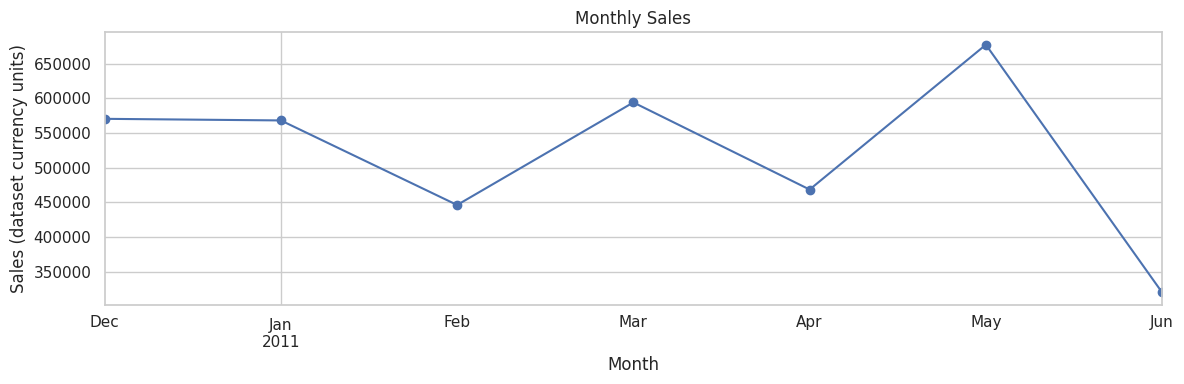

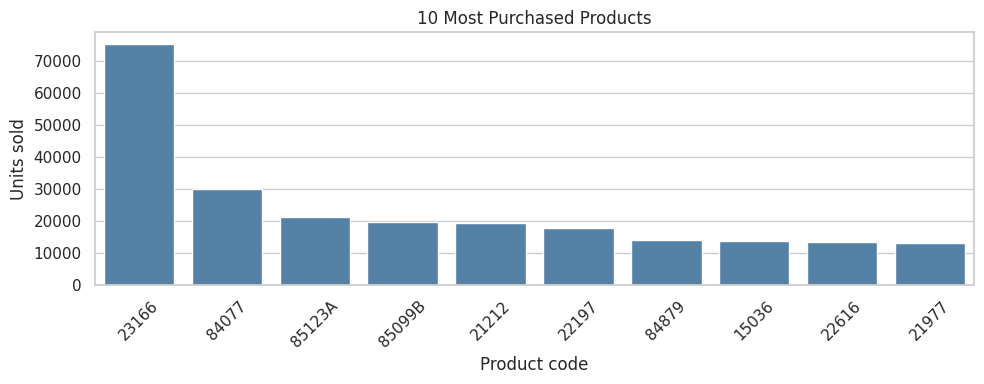

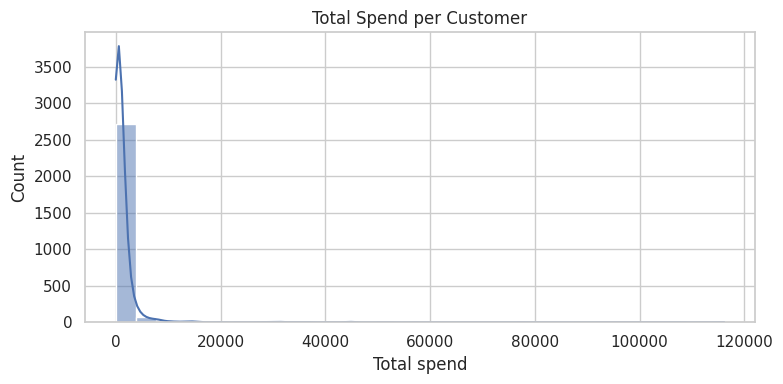

In [5]:
print("Summary of transaction values:")
display(df[["Quantity", "UnitPrice", "LineSpend"]].describe().round(2))

monthly_sales = df.groupby("Month")["LineSpend"].sum().sort_index()
plt.figure(figsize=(12, 4))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (dataset currency units)")
plt.tight_layout()
plt.show()

top_products = (df.groupby("StockCode")["Quantity"].sum()
                  .sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 4))
sns.barplot(x=top_products.index.astype(str), y=top_products.values, color="steelblue")
plt.title("10 Most Purchased Products")
plt.xlabel("Product code")
plt.ylabel("Units sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

customer_sales = df.groupby("CustomerID")["LineSpend"].sum()
plt.figure(figsize=(8, 4))
sns.histplot(customer_sales, bins=30, kde=True)
plt.title("Total Spend per Customer")
plt.xlabel("Total spend")
plt.tight_layout()
plt.show()

## 6. Create monthly customer features and next-month targets

For each customer and month, we summarize current-month orders, units, and spend. The target is that same customer's spend and purchase activity in the following calendar month. **Why:** using an earlier month to predict a later month respects time order and makes “future” prediction meaningful. Customers with no purchase in a month receive zero spend for that month.

In [6]:
monthly_customer = df.groupby(["CustomerID", "Month"]).agg(
    Orders=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum"),
    Spend=("LineSpend", "sum"),
    Products=("StockCode", "nunique")
).reset_index()

all_months = pd.date_range(df["Month"].min(), df["Month"].max(), freq="MS")
all_customers = monthly_customer["CustomerID"].unique()
full_index = pd.MultiIndex.from_product([all_customers, all_months], names=["CustomerID", "Month"])
panel = (monthly_customer.set_index(["CustomerID", "Month"])
         .reindex(full_index, fill_value=0).reset_index())
panel["Orders"] = panel["Orders"].astype(int)
panel["Units"] = panel["Units"].astype(float)
panel["Spend"] = panel["Spend"].astype(float)
panel["Products"] = panel["Products"].astype(int)

panel["NextMonthSpend"] = panel.groupby("CustomerID")["Spend"].shift(-1)
panel["NextMonthPurchase"] = (panel["NextMonthSpend"] > 0).astype(int)
model_data = panel.dropna(subset=["NextMonthSpend"]).copy()
model_data["MonthNumber"] = model_data["Month"].dt.month

feature_columns = ["Orders", "Units", "Spend", "Products", "MonthNumber"]
print("Customer-month examples:", len(model_data))
print("Months available:", model_data["Month"].min().date(), "to", model_data["Month"].max().date())
display(model_data.head())

Customer-month examples: 17016
Months available: 2010-12-01 to 2011-05-01


,CustomerID,Month,Orders,Units,Spend,Products,NextMonthSpend,NextMonthPurchase,MonthNumber
0,12346,2010-12-01,0,0.0,0.0,0,77183.6,1,12
1,12346,2011-01-01,1,74215.0,77183.6,1,0.0,0,1
2,12346,2011-02-01,0,0.0,0.0,0,0.0,0,2
3,12346,2011-03-01,0,0.0,0.0,0,0.0,0,3
4,12346,2011-04-01,0,0.0,0.0,0,0.0,0,4


## 7. Split training and test data by time

Earlier customer-month records are used for training; the latest month with a known following month is held out for testing. **Why:** a random split could let future patterns leak into the past. A time-based split better reflects the way a business would use the model.

In [7]:
latest_feature_month = model_data["Month"].max()
train_data = model_data[model_data["Month"] < latest_feature_month].copy()
test_data = model_data[model_data["Month"] == latest_feature_month].copy()

if train_data.empty or test_data.empty:
    raise ValueError("Not enough consecutive months to create a time-based train/test split.")

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]
y_spend_train = train_data["NextMonthSpend"]
y_spend_test = test_data["NextMonthSpend"]
y_buy_train = train_data["NextMonthPurchase"]
y_buy_test = test_data["NextMonthPurchase"]

print("Training feature month range:", train_data["Month"].min().date(), "to", train_data["Month"].max().date())
print("Test feature month:", latest_feature_month.date())
print("Training examples:", len(train_data), "| Test examples:", len(test_data))
print("Training purchase/no-purchase counts:")
print(y_buy_train.value_counts().rename(index={0: "No purchase next month", 1: "Purchased next month"}))

Training feature month range: 2010-12-01 to 2011-04-01
Test feature month: 2011-05-01
Training examples: 14180 | Test examples: 2836
Training purchase/no-purchase counts:
NextMonthPurchase
No purchase next month    9795
Purchased next month      4385
Name: count, dtype: int64


## 8. Linear Regression: predict next-month spending

The model learns a relationship between a customer's current-month activity and their spending in the following month. **Why:** this provides a simple spending forecast. It is a baseline, not a guarantee; check its errors and remember predictions cannot be negative in real spending.

In [8]:
spend_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])
spend_model.fit(X_train, y_spend_train)
spend_predictions = np.maximum(0, spend_model.predict(X_test))

mae = mean_absolute_error(y_spend_test, spend_predictions)
rmse = np.sqrt(mean_squared_error(y_spend_test, spend_predictions))
r2 = r2_score(y_spend_test, spend_predictions)
print(f"Mean absolute error: {mae:.2f} spend units")
print(f"Root mean squared error: {rmse:.2f} spend units")
print(f"R-squared: {r2:.3f}")

spend_results = test_data[["CustomerID", "Month", "NextMonthSpend"]].copy()
spend_results["PredictedNextMonthSpend"] = spend_predictions
display(spend_results.head(10).round(2))

Mean absolute error: 243.98 spend units
Root mean squared error: 1080.65 spend units
R-squared: 0.095


,CustomerID,Month,NextMonthSpend,PredictedNextMonthSpend
5,12346,2011-05-01,0.00,114.33
12,12347,2011-05-01,382.52,114.33
19,12348,2011-05-01,0.00,114.33
26,12350,2011-05-01,0.00,114.33
33,12352,2011-05-01,0.00,114.33
40,12353,2011-05-01,0.00,224.02
47,12354,2011-05-01,0.00,114.33
54,12355,2011-05-01,0.00,310.74
61,12356,2011-05-01,0.00,114.33
68,12359,2011-05-01,1109.32,114.33


## 9. Logistic Regression: probability of a purchase next month

The target is `1` if the customer buys anything in the next calendar month, and `0` otherwise. **Why:** Logistic Regression estimates a probability for this two-outcome question. It does not estimate the chance of buying a specific product; this dataset has transactions but no product views or unpurchased-item labels.

In [9]:
if y_buy_train.nunique() < 2:
    print("This training period contains only one purchase outcome. Logistic Regression needs both 0 and 1 examples, so this section cannot be fitted from the current time split.")
    purchase_model = None
else:
    purchase_model = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
    purchase_model.fit(X_train, y_buy_train)
    purchase_probability = purchase_model.predict_proba(X_test)[:, 1]
    purchase_prediction = (purchase_probability >= 0.5).astype(int)

    print(f"Accuracy:  {accuracy_score(y_buy_test, purchase_prediction):.3f}")
    print(f"Precision: {precision_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print(f"F1 score:  {f1_score(y_buy_test, purchase_prediction, zero_division=0):.3f}")
    print("Confusion matrix [actual rows 0/1, predicted columns 0/1]:")
    print(confusion_matrix(y_buy_test, purchase_prediction, labels=[0, 1]))

Accuracy:  0.613
Precision: 0.224
Recall:    0.439
F1 score:  0.297
Confusion matrix [actual rows 0/1, predicted columns 0/1]:
[[1506  802]
 [ 296  232]]


## 10. K-Means: customer segments

We group customers using recency (days since last order), frequency (number of distinct invoices), and monetary value (total spend). **Why:** these familiar RFM measures describe how recently and often customers buy and how much they spend. Cluster numbers are arbitrary; this section assigns understandable names by ranking average spend. “Premium,” “Regular,” and “Occasional” are convenient labels, not natural facts about customers.

In [10]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    RecencyDays=("InvoiceDate", lambda dates: (snapshot_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineSpend", "sum")
)

cluster_count = min(3, len(rfm))
if cluster_count < 2:
    raise ValueError("At least two customers are needed for customer segmentation.")

rfm_features = np.log1p(rfm[["RecencyDays", "Frequency", "Monetary"]].clip(lower=0))
cluster_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=cluster_count, random_state=42, n_init=10))
])
rfm["Cluster"] = cluster_pipeline.fit_predict(rfm_features)
spend_rank = rfm.groupby("Cluster")["Monetary"].mean().sort_values(ascending=False)
segment_names = {cluster: name for cluster, name in zip(spend_rank.index, ["Premium", "Regular", "Occasional"])}
rfm["Segment"] = rfm["Cluster"].map(segment_names)
print("Average RFM values by segment:")
display(rfm.groupby("Segment")[["RecencyDays", "Frequency", "Monetary"]].mean().round(1))
print("Customer segment counts:")
display(rfm["Segment"].value_counts().rename_axis("Segment").to_frame("Customers"))

Average RFM values by segment:


,RecencyDays,Frequency,Monetary
Segment,,,
Occasional,109.5,1.2,320.7
Premium,18.8,8.9,5175.4
Regular,34.4,2.4,887.2


Customer segment counts:


,Customers
Segment,
Occasional,1339
Regular,1057
Premium,440


## 11. KNN-style personalized product recommendations

For each customer, we compare their product-purchase history with other customers using cosine similarity. We then suggest products bought by the closest customers that this customer has not bought. **Why:** this is a simple collaborative-filtering baseline based on shared purchasing patterns. Recommendations are not personalized from ratings because the dataset has no ratings.

In [11]:
customer_codes, customer_values = pd.factorize(df["CustomerID"])
product_codes, product_values = pd.factorize(df["StockCode"])
interaction = csr_matrix(
    (df["Quantity"].to_numpy(dtype=float), (customer_codes, product_codes)),
    shape=(len(customer_values), len(product_values))
)

neighbor_count = min(6, len(customer_values))
knn_model = NearestNeighbors(n_neighbors=neighbor_count, metric="cosine", algorithm="brute")
knn_model.fit(interaction)
customer_to_row = {customer: row for row, customer in enumerate(customer_values)}
product_to_col = {product: col for col, product in enumerate(product_values)}

# Prompt: enter a CustomerID exactly as shown in the dataset preview (example: 17850).
selected_customer = input("Enter a CustomerID from the dataset preview (example: 17850): ").strip()
if selected_customer not in customer_to_row:
    print("That CustomerID was not found. Copy one exactly from the CustomerID column and run this section again.")
else:
    row_number = customer_to_row[selected_customer]
    distances, neighbors = knn_model.kneighbors(interaction[row_number], n_neighbors=neighbor_count)
    neighbor_rows = [int(r) for r in neighbors[0] if int(r) != row_number]
    already_bought = set(interaction[row_number].indices)
    candidate_scores = {}
    for distance, neighbor_row in zip(distances[0], neighbors[0]):
        neighbor_row = int(neighbor_row)
        if neighbor_row == row_number:
            continue
        similarity = 1 - float(distance)
        for product_col in interaction[neighbor_row].indices:
            if product_col not in already_bought:
                candidate_scores[product_col] = candidate_scores.get(product_col, 0) + similarity
    recommended_cols = sorted(candidate_scores, key=candidate_scores.get, reverse=True)[:10]
    if not recommended_cols:
        print("No unseen products could be recommended for this customer from the nearest neighbors.")
    else:
        recommendations = pd.DataFrame({
            "ProductCode": [str(product_values[col]) for col in recommended_cols],
            "NeighborSimilarityScore": [candidate_scores[col] for col in recommended_cols]
        })
        print("Suggested products (higher similarity score means more support from similar customers):")
        display(recommendations)

Enter a CustomerID from the dataset preview (example: 17850): 15311
Suggested products (higher similarity score means more support from similar customers):


,ProductCode,NeighborSimilarityScore
0,84991,0.973797
1,22837,0.973797
2,21213,0.973797
3,23209,0.973797
4,21363,0.636773
5,20749,0.636773
6,22423,0.636773
7,21509,0.636773
8,22617,0.636773
9,22514,0.636773


## 12. Show results for one customer

Enter a customer ID that appears in the dataset. **What to type:** copy an ID from the `CustomerID` column shown in the previews; do not type a customer's name. The report shows their RFM segment, next-month spend forecast, and—when Logistic Regression could be trained—next-month purchase probability. Predictions are based on the latest available customer-month features.

In [12]:
customer_id_for_report = input("Enter a CustomerID from the dataset preview (example: 17850): ").strip()

if customer_id_for_report not in customer_to_row:
    print("CustomerID not found. Copy an ID exactly from the dataset preview and run this section again.")
else:
    customer_transactions = df[df["CustomerID"] == customer_id_for_report]
    segment = rfm.loc[customer_id_for_report, "Segment"]
    customer_months = panel[panel["CustomerID"] == customer_id_for_report].sort_values("Month")
    latest_customer_month = customer_months.iloc[-1]
    customer_features = pd.DataFrame([{
        "Orders": latest_customer_month["Orders"],
        "Units": latest_customer_month["Units"],
        "Spend": latest_customer_month["Spend"],
        "Products": latest_customer_month["Products"],
        "MonthNumber": latest_customer_month["Month"].month
    }], columns=feature_columns)
    predicted_spend = max(0, float(spend_model.predict(customer_features)[0]))

    print("Customer:", customer_id_for_report)
    print("Segment:", segment)
    print("Historical total spend:", round(float(rfm.loc[customer_id_for_report, "Monetary"]), 2))
    print("Predicted spend for the next calendar month:", round(predicted_spend, 2), "dataset currency units")
    if purchase_model is not None:
        probability = float(purchase_model.predict_proba(customer_features)[0, 1])
        print(f"Estimated probability of any purchase next month: {probability:.1%}")
    else:
        print("Purchase probability is unavailable because the training data did not contain both purchase and no-purchase outcomes.")
    print("Orders in file:", customer_transactions["InvoiceNo"].nunique())

Enter a CustomerID from the dataset preview (example: 17850): 16098
Customer: 16098
Segment: Premium
Historical total spend: 1222.22
Predicted spend for the next calendar month: 256.2 dataset currency units
Estimated probability of any purchase next month: 55.2%
Orders in file: 4


## 13. Interpretation, limitations, and next steps

- **Spending forecast:** MAE and RMSE are in dataset currency units; lower is better. A negative R² can mean the model performed worse than a simple average baseline.
- **Purchase probability:** this predicts a purchase in the next calendar month. It does not predict conversion after a product view because the data has no browsing sessions or exposed-but-not-purchased products.
- **Recommendations:** these are product codes supported by similar customer histories. Product descriptions can be joined in if the chosen dataset includes them.
- **Segments:** K-Means is unsupervised. Names are assigned from the clusters' average spend to make the output easier to discuss; use all three RFM measures when interpreting the groups.
- **Data limitations:** this Kaggle dataset has no demographics, browsing activity, or product ratings. Do not claim those were analyzed. Choose a dataset containing those fields if the assignment requires them specifically.
- **Validation:** the time split is more realistic than a random split, but one test month can be unusual. For a stronger project, evaluate across several rolling months and compare with simple baselines.

## 14. Student conclusion

Write your own short conclusion after running the notebook:

1. Which month and products had the strongest sales in your results?
2. What were the spending model's MAE and RMSE, and what do those values mean in the dataset's currency?
3. Which customer segment had the largest average spend?
4. What recommendation did you receive for your selected customer?
5. What extra dataset fields would improve this project (for example, product views, product ratings, or demographics)?


## 14. Conclusion

Using the cleaned Kaggle Online Retail data, **November 2011** had the highest sales, totaling **£1,156,205.61**. The most purchased products by quantity were **PAPER CRAFT, LITTLE BIRDIE** (80,995 units), **MEDIUM CERAMIC TOP STORAGE JAR** (77,916 units), and **WORLD WAR 2 GLIDERS ASSTD DESIGNS** (54,319 units).

The Linear Regression model achieved an **MAE of £288.53** and an **RMSE of £2,607.41** on the held-out month. MAE means its predictions were off by about £288.53 on average; RMSE penalizes large errors more, and its much higher value shows that some predictions were far off. The model's **R² was -0.007**, so this baseline did not predict future spending reliably on the test month.

K-Means assigned the highest average-spend group the **Premium** label, with average historical spend of about **£7,898.50** per customer. For example customer **17850**, the KNN-style recommender suggested **3 HOOK PHOTO SHELF ANTIQUE WHITE**, **PICTURE FRAME WOOD TRIPLE PORTRAIT**, and **CREAM SWEETHEART MINI CHEST**, among its top recommendations.

Adding product views, browsing sessions, add-to-cart events, product ratings, and customer demographic fields would support richer behavior analysis and product-specific purchase predictions. This dataset does not contain those fields, so the current purchase model estimates whether a customer buys anything in a later month.

*These are the results from running the notebook using the CSV path shown in the user's screenshot and CustomerID 17850 for the example recommendation.*